# 05 · MWC — รวมหลายดัชนีแล้วอธิบายได้มากขึ้นจริงไหม

**โครงงาน Sea Level × Wavelet Coherence · วิชา 01204496 · สัปดาห์ที่ 5 (W5)**

W5 สร้างเครื่องมือสองชิ้นที่ W6 (ค้นครบทุกชุด · Q3–Q6) ต้องใช้ และพิสูจน์ว่ามันถูก

| ชิ้น | ที่อยู่ | ตรวจด้วย |
| --- | --- | --- |
| `mwc()` · `SpectraCache` · `mwc_cached()` | `wtc/coherence.py` | q = 1 ต้องเท่ากับ WTC · Hermitian/บวกแน่นอน · condition number ทุกจุด · 13 เทสต์ใน `tests/test_mwc.py` |
| `threshold_mwc()` · `pasc_null_mwc()` | `wtc/significance.py` | q = 1 แบบเจาะจงต้องได้เลขเดียวกับ `threshold_wtc` ทุกหลัก · null ต้องให้ PASC เฉลี่ย ≈ 5% |

null ที่ใช้จริงคำนวณด้วย `scripts/run_mwc_null.py` (ผลใน `data/processed/mwc_null.npz`) โน้ตบุ๊กนี้อ่านผล
ตรวจซ้ำ แล้วลองใช้กับข้อมูลจริงแบบ **ตัวอย่าง** (การค้นครบ 218 ชุดคือ W6)

```
Y, X1..Xq ─> CWT ─> spectrum ที่ smooth แล้วต่อคู่ (cache 45 อันต่อสถานี) ─> ประกอบเมทริกซ์ q×q ─> solve ทุกจุด ─> rho²
AR(1) ของ Y + ดัชนี 8 ตัว ─> surrogate 1000 ชุด (สุ่มชุดดัชนีขนาด q ใหม่ทุกครั้ง) ─> threshold 95% ต่อ (q, สเกล)
AR(1) ชุดใหม่อีก 1000 ─> การกระจายของ PASC ใน null ต่อ q ─> p-value ของ PASC
```

## การตัดสินใจที่ต้องประกาศในรายงาน

| เรื่อง | ที่เลือก | เหตุผล |
| --- | --- | --- |
| จุดที่เมทริกซ์เกือบ singular | condition number > 1e8 ⇒ NaN · **ไม่ regularize** | MWC นิยามได้ทุกครั้งที่เมทริกซ์บวกแน่นอน เหตุผลเดียวที่ต้องทิ้งคือความแม่นของเลขทศนิยม (cond × 1e-16) — หัวข้อ 3 |
| null ของ MWC | Y และดัชนีทั้ง q ตัว **อิสระต่อกันหมด** แต่ละตัวมี a ของตัวเอง | ตามแบบ Hu & Si (2016) |
| รวม null ต่อ (q, สถานี) | ทุก surrogate สุ่มชุดขนาด q ใหม่จาก 8 ดัชนี ⇒ threshold เดียวต่อ q | ถูกกว่า null แยกทุกชุด ~50 เท่า · หัวข้อ 6 วัดแล้วว่าต่างจาก null เจาะจงชุดแค่ระดับ 0.01 |
| threshold ขึ้นกับ q | **ใช้ threshold ของ q ตัวเองเสมอ** | หัวข้อ 5: noise ล้วน 5 ตัวได้ rho² สูงถึง ~0.96 |

In [1]:
import json, sys, time
from itertools import combinations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from wtc.coherence import COND_MAX, SpectraCache, coherency_matrix, mwc, mwc_cached, wtc
from wtc.metrics import BANDS, awc, pasc, significance, valid_mask
from wtc.significance import ar1_surrogate, empirical_p, fit_ar1, threshold_mwc
from wtc.transform import DJ, DT_MONTHLY, coi_mask, cwt
from wtc.plotting import period_axis, plot_coherence, use_thai_font

FIGURES = ROOT / "figures"; FIGURES.mkdir(exist_ok=True)
use_thai_font()

d = np.load(ROOT / "data" / "processed" / "series.npz", allow_pickle=True)
nul = np.load(ROOT / "data" / "processed" / "mwc_null.npz", allow_pickle=True)
meta = json.loads(str(nul["meta"]))
t = d["t"]
yn = [str(s) for s in d["y_names"]]; xn = [str(s) for s in d["x_names"]]
stations = [str(s) for s in nul["stations"]]; QS = [int(q) for q in nul["qs"]]
bands = [str(b) for b in nul["bands"]]
MAIN = stations[0]
NAME = {"nino34": "Niño3.4", "soi": "SOI", "pdo": "PDO", "amo": "AMO", "nao": "NAO",
        "tpi": "TPI", "dmi": "DMI", "wnpmi": "WNPMI"}

y, y_fill = d["Y"][yn.index(MAIN)], d["Y_fill"][yn.index(MAIN)]
X = {k: d["X"][j] for j, k in enumerate(xn)}
X_fill = {k: d["X_fill"][j] for j, k in enumerate(xn)}
Wy, scales, periods, coi = cwt(y)
W = {"y": Wy, **{k: cwt(X[k])[0] for k in xn}}
cache = SpectraCache(W, DT_MONTHLY, DJ, scales)
inside = coi_mask(periods, coi)

thr = {q: nul["threshold"][0, i] for i, q in enumerate(QS)}          # สถานีหลัก
null = {q: {b: nul["null"][0, i, k] for k, b in enumerate(bands)} for i, q in enumerate(QS)}
print(f"สถานีหลัก {MAIN} · ระนาบ {Wy.shape[0]} สเกล × {Wy.shape[1]} เดือน · "
      f"null {meta['nmc']} surrogate ต่อ q · seed {meta['seed']}")
assert MAIN == "ko_taphao_noi" and meta["nmc"] >= 1000
assert np.allclose(nul["periods"], periods)

สถานีหลัก ko_taphao_noi · ระนาบ 107 สเกล × 865 เดือน · null 1000 surrogate ต่อ q · seed 20261001


## 1. MWC คืออะไร — R² ของถดถอยพหุ ที่คิดแยกทุกจุด (s, t)

สมการ (4)–(6) ของเปเปอร์ต้นทาง (ยกมาจาก Hu & Si 2016) — ตัวหยักทุกตัวคือผ่าน smoothing แล้ว

$$
\rho_m^2(s,t)=\frac{\widetilde{W}^{Y,X}\,[\widetilde{W}^{X,X}]^{-1}\,\widetilde{W}^{Y,X\,*}}{\widetilde{W}^{Y,Y}}
$$

โค้ดของเราคำนวณในรูปที่ normalize แล้ว (พีชคณิตเหมือนกันทุกตัว แต่เลขดีกว่าและอ่านง่ายกว่า)

$$
u_i=\frac{\widetilde{W}^{Y,X_i}}{\sqrt{\widetilde{W}^{Y,Y}\,\widetilde{W}^{X_i,X_i}}}\qquad
C_{ij}=\frac{\widetilde{W}^{X_i,X_j}}{\sqrt{\widetilde{W}^{X_i,X_i}\,\widetilde{W}^{X_j,X_j}}}\qquad
\rho_m^2=u\,C^{-1}u^{H}
$$

เทียบตัวต่อตัวกับถดถอยพหุ $R^2 = r^\top R^{-1} r$ — $u$ คือ "สหสัมพันธ์" ของ Y กับดัชนีแต่ละตัว
$C$ คือ "เมทริกซ์สหสัมพันธ์" ระหว่างดัชนีด้วยกัน ต่างกันแค่เป็นจำนวนเชิงซ้อนและคิดแยกทุกจุดบนระนาบ
และ $|u_i|^2$ คือ WTC ของ Y กับ $X_i$ พอดี ⇒ ที่ q = 1 สูตรยุบเหลือ WTC

**ตัวอย่างที่เห็นภาพที่สุด**: ถ้า Y = X1 + X2 เป๊ะ WTC กับทีละตัวจะไม่ถึง 1 แต่ MWC ของทั้งคู่ = 1 ทุกจุด

WTC(Y, X1)       เฉลี่ยในกรวย 0.599 · ต่ำสุด 0.000
WTC(Y, X2)       เฉลี่ยในกรวย 0.624 · ต่ำสุด 0.000
MWC(Y; X1, X2)   เฉลี่ยในกรวย 1.000 · ต่ำสุด 1.000


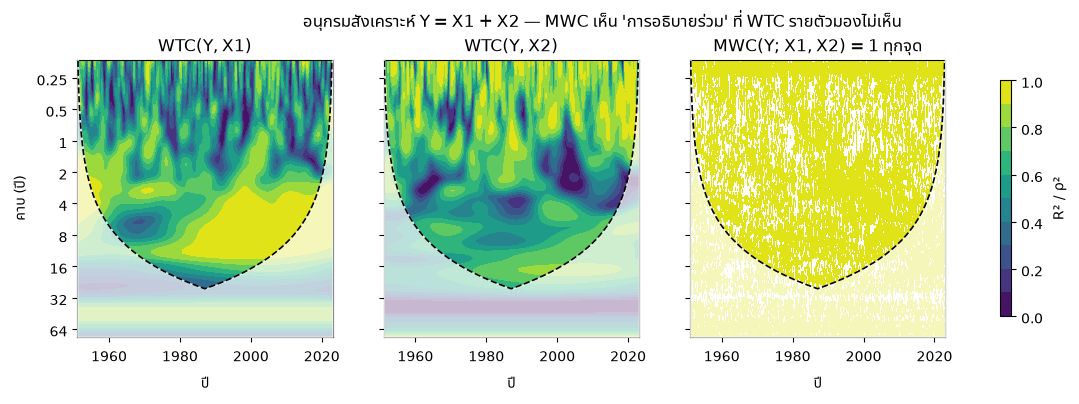

In [2]:
rng = np.random.default_rng(0)
x1 = ar1_surrogate(len(t), 0.8, 0.6, rng); x2 = ar1_surrogate(len(t), 0.5, 0.87, rng)
W1, sc_, per_, coi_ = cwt(x1); W2 = cwt(x2)[0]; Ws = cwt(x1 + x2)[0]
r1, _ = wtc(Ws, W1, DT_MONTHLY, DJ, sc_)
r2, _ = wtc(Ws, W2, DT_MONTHLY, DJ, sc_)
rm, _ = mwc(Ws, [W1, W2], DT_MONTHLY, DJ, sc_)
ins_ = coi_mask(per_, coi_)
for lab, R in (("WTC(Y, X1)", r1), ("WTC(Y, X2)", r2), ("MWC(Y; X1, X2)", rm)):
    print(f"{lab:16s} เฉลี่ยในกรวย {R[ins_].mean():.3f} · ต่ำสุด {R[ins_].min():.3f}")
assert np.abs(rm[ins_] - 1).max() < 1e-10

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, R, ttl in zip(axes, (r1, r2, rm), ("WTC(Y, X1)", "WTC(Y, X2)", "MWC(Y; X1, X2) = 1 ทุกจุด")):
    cf = plot_coherence(ax, t, per_, R, coi_, title=ttl)
    ax.set_ylabel("")
axes[0].set_ylabel("คาบ (ปี)")
fig.colorbar(cf, ax=axes, shrink=0.85, label="R² / ρ²")
fig.suptitle("อนุกรมสังเคราะห์ Y = X1 + X2 — MWC เห็น 'การอธิบายร่วม' ที่ WTC รายตัวมองไม่เห็น", y=1.02)
fig.savefig(FIGURES / "w5-mwc-exact-sum.png", dpi=130, bbox_inches="tight")

## 2. ตัวตรวจที่ได้มาฟรี — MWC ที่ q = 1 ต้องเท่ากับ WTC (เกณฑ์ 1e-10)

WTC ผ่านประตู G1 มาแล้ว (ตรงกับ `pycwt.wct` ระดับ 1e-15) ⇒ ถ้า MWC ที่ q = 1 เท่ากับ WTC
ก็แปลว่าเส้นทางใหม่ทั้งหมด (cache ของคู่ · การประกอบ u · การ normalize) ไม่ได้ทำให้อะไรเพี้ยน

In [3]:
worst = {}
for k in xn:
    a, _ = wtc(Wy, W[k], DT_MONTHLY, DJ, scales)
    b, cond = mwc_cached(cache, "y", [k])
    worst[k] = float(np.max(np.abs(a - b)))
print("max |MWC(q=1) − WTC| ทั้งระนาบ ที่ KO TAPHAO NOI")
for k, v in worst.items():
    print(f"  {NAME[k]:8s} {v:.1e}")
assert max(worst.values()) < 1e-10
print(f"✅ ทั้ง 8 ดัชนีต่างไม่เกิน {max(worst.values()):.1e} (เกณฑ์ 1e-10)")

max |MWC(q=1) − WTC| ทั้งระนาบ ที่ KO TAPHAO NOI
  Niño3.4  6.7e-16
  SOI      7.8e-16
  PDO      7.8e-16
  AMO      7.8e-16
  NAO      7.8e-16
  TPI      6.7e-16
  DMI      6.7e-16
  WNPMI    7.8e-16
✅ ทั้ง 8 ดัชนีต่างไม่เกิน 7.8e-16 (เกณฑ์ 1e-10)


## 3. เมทริกซ์เกือบ singular — ที่กลัวไว้เกิดจริงไหม และเกิดที่ไหน

PLAN.md §8 กลัวว่า Niño3.4 กับ SOI (ขาทะเลกับขาบรรยากาศของ ENSO ตัวเดียวกัน) จะทำให้ $C$ เกือบ singular
ตรวจสองอย่าง: (ก) คู่ Niño3.4–SOI โดยตรง (ข) **ทุกชุดดัชนี 218 ชุด** ที่ W6 จะใช้ — condition number ทุกจุด

In [4]:
C = coherency_matrix(cache, ["nino34", "soi"])
coh2 = np.abs(C[..., 0, 1]) ** 2
ev = np.linalg.eigvalsh(C[inside])
_, cond_ns = mwc_cached(cache, "y", ["nino34", "soi"])
print(f"WTC(Niño3.4, SOI) ในกรวย: มัธยฐาน {np.median(coh2[inside]):.2f} · สูงสุด {coh2[inside].max():.3f}")
print(f"ค่าลักษณะเฉพาะต่ำสุดในกรวย {ev.min():.3f} (> 0 = บวกแน่นอน) · cond สูงสุดในกรวย {cond_ns[inside].max():.0f}")
assert np.allclose(C, np.conj(np.swapaxes(C, -1, -2))) and ev.min() > 0

subsets = [s for q in QS for s in combinations(xn, q)]
t0 = time.perf_counter()
worst_cond, nan_in, nan_out = {}, 0, 0
for s in subsets:
    R2, cond = mwc_cached(cache, "y", s)
    worst_cond[s] = float(cond[inside].max())
    nan_in += int(np.isnan(R2[inside]).sum()); nan_out += int(np.isnan(R2[~inside]).sum())
print(f"\nทุกชุด {len(subsets)} ชุด ({time.perf_counter() - t0:.0f} วินาที · cache {len(cache)} อัน {cache.nbytes / 1e6:.0f} MB)")
print(f"  จุด NaN ในกรวย {nan_in} · นอกกรวย {nan_out}")
top = sorted(worst_cond.items(), key=lambda kv: -kv[1])[:3]
for s, c in top:
    print(f"  cond สูงสุดในกรวย {c:9.0f}  ← {'+'.join(NAME[k] for k in s)}")
assert nan_in == 0 and len(cache) == 1 + 8 + 36

WTC(Niño3.4, SOI) ในกรวย: มัธยฐาน 0.71 · สูงสุด 0.980
ค่าลักษณะเฉพาะต่ำสุดในกรวย 0.010 (> 0 = บวกแน่นอน) · cond สูงสุดในกรวย 198



ทุกชุด 218 ชุด (26 วินาที · cache 45 อัน 60 MB)
  จุด NaN ในกรวย 0 · นอกกรวย 1117720
  cond สูงสุดในกรวย     63091  ← Niño3.4+SOI+PDO+NAO+WNPMI
  cond สูงสุดในกรวย     49556  ← Niño3.4+SOI+AMO+TPI+WNPMI
  cond สูงสุดในกรวย     39393  ← Niño3.4+AMO+NAO+TPI+DMI


จุดที่เกิน 1e8: 10380 จุด · คาบ 40–76 ปี · ในกรวย 0


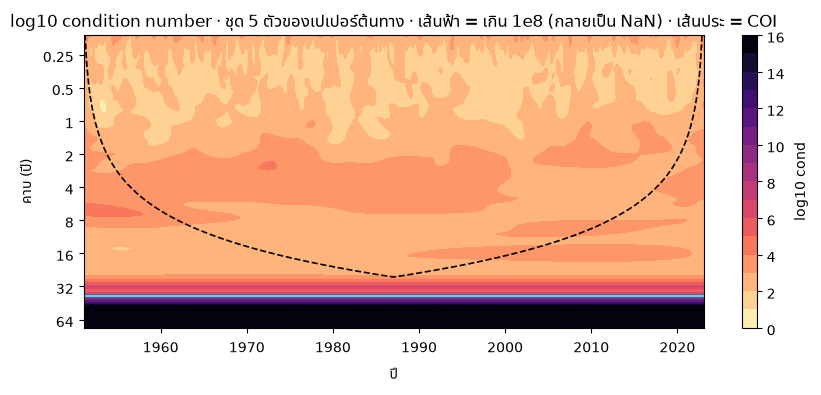

In [5]:
PAPER = ["nino34", "pdo", "nao", "amo", "tpi"]          # ลำดับที่เปเปอร์ต้นทางเพิ่มทีละตัว
_, cond5 = mwc_cached(cache, "y", PAPER, cond_max=1e14)
fig, ax = plt.subplots(figsize=(10, 3.8))
cf = ax.contourf(t, periods, np.log10(np.clip(cond5, 1, 1e16)), levels=np.arange(0, 17, 1), cmap="magma_r")
ax.contour(t, periods, (cond5 > COND_MAX).astype(float), levels=[0.5], colors="cyan", linewidths=1.4)
ax.plot(t, coi, "k--", lw=1.2)
period_axis(ax, periods); ax.set_xlabel("ปี")
ax.set_title("log10 condition number · ชุด 5 ตัวของเปเปอร์ต้นทาง · เส้นฟ้า = เกิน 1e8 (กลายเป็น NaN) · เส้นประ = COI")
fig.colorbar(cf, ax=ax, label="log10 cond")
fig.savefig(FIGURES / "w5-condition-number.png", dpi=130, bbox_inches="tight")
bad = cond5 > COND_MAX
print(f"จุดที่เกิน 1e8: {bad.sum()} จุด · คาบ {periods[bad.any(axis=1)].min():.0f}–{periods.max():.0f} ปี · ในกรวย {int((bad & inside).sum())}")

**อ่านผล** — ที่กลัวไว้ไม่เกิด: Niño3.4 กับ SOI สัมพันธ์กันสูง (WTC มัธยฐาน ~0.7) แต่ไม่ถึงขั้นทำให้เมทริกซ์เสีย
จุดที่เสียจริงอยู่ที่ **คาบยาวมาก (≥ 40 ปี) ซึ่งอยู่นอก COI ทั้งหมด** — ที่สเกลนั้นหน้าต่าง smoothing กว้างกว่า
ข้อมูลทั้งเส้น เพื่อนบ้านที่เฉลี่ยเข้ามาแทบไม่เป็นอิสระต่อกัน เมทริกซ์ q × q จึงมี "ข้อมูลอิสระ" ไม่ถึง q ชิ้น

⚠️ กลไกเดียวกันนี้คือต้นเหตุของหัวข้อ 5: **ถ้าจำนวนข้อมูลอิสระในหน้าต่างมีน้อย การเพิ่มตัวทำนายจะดัน ρ² เข้าหา 1
ได้เองแม้ตัวทำนายเป็น noise** — เหมือนถดถอยพหุที่มีตัวแปรเกือบเท่าจำนวนข้อมูล

## 4. การ normalize ขอบแกนสเกลยังหารกันหายไหม (ค้างมาจาก G1 ข้อ 3)

ตอน G1 พบว่าการ normalize ขอบแกนสเกล "ไม่มีผลต่อ WTC เลย" เพราะคูณทั้งแถวด้วยค่าเดียวกัน
ใน MWC ทุกพจน์ที่จุดเดียวกันผ่านตัวดำเนินการเดียวกัน ⇒ ค่าคงที่ c ออกมาเป็น c² / c ในเศษ และ c ในส่วน ⇒ หายเหมือนกัน

In [6]:
Wl = [W[k] for k in PAPER[:3]]
a, _ = mwc(Wy, Wl, DT_MONTHLY, DJ, scales)
b, _ = mwc(Wy, Wl, DT_MONTHLY, DJ, scales, compat=True)
diff = np.nanmax(np.abs(a - b))
print(f"MWC q=3 · ขอบแกนสเกลแบบ normalize (ของเรา) เทียบแบบปล่อย (pycwt) ต่างสูงสุด {diff:.1e}")
assert diff < 1e-12

MWC q=3 · ขอบแกนสเกลแบบ normalize (ของเรา) เทียบแบบปล่อย (pycwt) ต่างสูงสุด 9.5e-15


## 5. ⭐ threshold ขึ้นกับจำนวนดัชนี q — ข้อค้นพบหลักของ W5

null ของ MWC = Y กับดัชนี q ตัวที่ **ไม่เกี่ยวกันเลย** (AR(1) อิสระ ความแดงเท่าของจริง)
threshold = เปอร์เซ็นไทล์ที่ 95 ของ ρ² จาก null นั้น แยกรายสเกล

มัธยฐานของ threshold ช่วงคาบ 0.5–16 ปี
      q=1     q=2     q=3     q=4     q=5
    0.591   0.770   0.872   0.930   0.962   ko_taphao_noi
    0.593   0.769   0.869   0.926   0.962   ko_lak
    0.598   0.770   0.873   0.930   0.964   fort_phrachula_chomklao


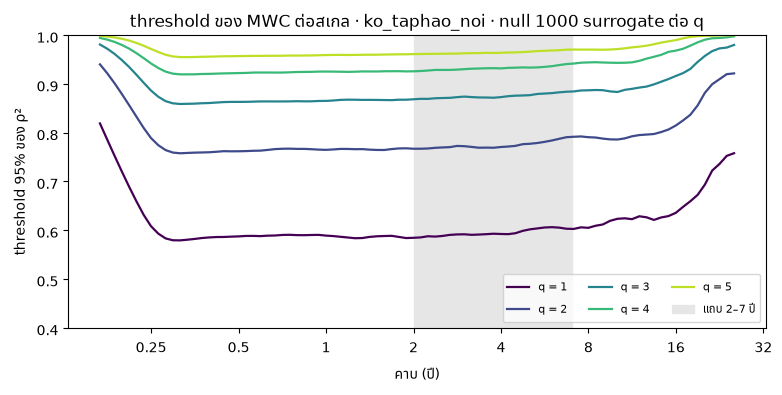

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
cols = plt.cm.viridis(np.linspace(0, 0.9, len(QS)))
for q, c in zip(QS, cols):
    ax.plot(periods, thr[q], color=c, lw=1.6, label=f"q = {q}")
ax.set_xscale("log", base=2)
ticks = [v for v in (0.25, 0.5, 1, 2, 4, 8, 16, 32, 64) if periods.min() <= v <= periods.max()]
ax.set_xticks(ticks); ax.set_xticklabels([f"{v:g}" for v in ticks]); ax.minorticks_off()
ax.axvspan(2, 7, color="0.9", zorder=0, label="แถบ 2–7 ปี")
ax.set_xlabel("คาบ (ปี)"); ax.set_ylabel("threshold 95% ของ ρ²"); ax.set_ylim(0.4, 1.0)
ax.set_title(f"threshold ของ MWC ต่อสเกล · {MAIN} · null {meta['nmc']} surrogate ต่อ q")
ax.legend(fontsize=8, ncol=3, loc="lower right")
fig.savefig(FIGURES / "w5-threshold-vs-q.png", dpi=130, bbox_inches="tight")

mid = (periods >= 0.5) & (periods <= 16)
print("มัธยฐานของ threshold ช่วงคาบ 0.5–16 ปี")
print("  " + " ".join(f"{'q=' + str(q):>7s}" for q in QS))
for i, st in enumerate(stations):
    vals = [np.nanmedian(nul["threshold"][i, j][mid]) for j in range(len(QS))]
    print("  " + " ".join(f"{v:7.3f}" for v in vals) + f"   {st}")
med = [np.nanmedian(thr[q][mid]) for q in QS]
assert all(a < b for a, b in zip(med, med[1:]))

In [8]:
from scipy.stats import beta
from scipy.optimize import brentq
# ถ้าหน้าต่าง smoothing มีข้อมูลอิสระ ν ชิ้นเท่า ๆ กัน multiple coherence ของ noise ~ Beta(q, ν − q)
nu = brentq(lambda v: beta.ppf(0.95, 1, v - 1) - med[0], 1.5, 60)
print(f"ν ที่ทำให้ Beta(1, ν−1) ได้ threshold q=1 ตรงกับจำลอง = {nu:.1f} ชิ้น")
print("  q   จำลอง   Beta(q, ν−q)")
for q, m in zip(QS, med):
    th = beta.ppf(0.95, q, nu - q) if nu > q else float("nan")
    print(f"  {q}   {m:.3f}   {th:.3f}")

ν ที่ทำให้ Beta(1, ν−1) ได้ threshold q=1 ตรงกับจำลอง = 4.4 ชิ้น
  q   จำลอง   Beta(q, ν−q)
  1   0.591   0.591
  2   0.770   0.823
  3   0.872   0.959
  4   0.930   1.000
  5   0.962   nan


In [9]:
print("PASC ของ null (%) — ค่าเฉลี่ย / เปอร์เซ็นไทล์ 95 · สถานีหลัก")
print(f"  {'q':>2s} " + " ".join(f"{b:>16s}" for b in bands))
for q in QS:
    print(f"  {q:2d} " + " ".join(f"{np.mean(null[q][b]):7.1f} / {np.percentile(null[q][b], 95):5.1f}" for b in bands))
means = [np.mean(null[q]["ทั้งระนาบ"]) for q in QS]
assert all(3.5 < m < 6.5 for m in means)
print(f"✅ PASC ทั้งระนาบของ null เฉลี่ย {min(means):.1f}–{max(means):.1f}% ทุก q — threshold ของแต่ละ q ทำหน้าที่ของมัน")

PASC ของ null (%) — ค่าเฉลี่ย / เปอร์เซ็นไทล์ 95 · สถานีหลัก
   q        ทั้งระนาบ           2–7 ปี          8–16 ปี
   1     5.1 /   9.0     5.0 /  13.6     5.1 /  27.3
   2     5.1 /   9.1     5.0 /  13.2     5.7 /  29.9
   3     5.1 /   8.9     4.8 /  12.7     6.0 /  28.3
   4     5.0 /   8.5     5.1 /  13.3     5.1 /  26.6
   5     5.0 /   8.2     5.1 /  12.0     5.6 /  26.2
✅ PASC ทั้งระนาบของ null เฉลี่ย 5.0–5.1% ทุก q — threshold ของแต่ละ q ทำหน้าที่ของมัน


**อ่านผล**

- threshold ขึ้นจาก **~0.59 ที่ q = 1 ไปถึง ~0.96 ที่ q = 5** และเหมือนกันแทบทุกหลักทั้งสามสถานี
  ⇒ ที่ q = 5 **noise ล้วน 5 ตัวได้ ρ² เกิน 0.96 ได้ 5% ของพื้นที่** — ค่า ρ² สูง ๆ ที่ q ใหญ่ไม่ได้แปลว่าอธิบายได้
- ทฤษฎีคร่าว ๆ (Beta ที่ ν คงที่) อธิบาย *ทิศทาง* และ *ขนาด* ได้: smoothing แบบ Grinsted ทิ้งข้อมูลอิสระไว้
  ในหน้าต่างเพียง ~4–6 ชิ้น แต่ตัวเลขไม่ตรงเป๊ะเพราะน้ำหนักของ Gaussian ไม่เท่ากันทุกจุด ⇒ **ใช้ค่าจากการจำลองเป็นหลัก**
  ทฤษฎีมีไว้อธิบายว่าทำไม
- เทียบกับเปเปอร์ต้นทาง: ชุด 5 ตัวของเขารายงาน **AWC ต่ำสุด 0.938** (docs/source-paper-detail.md §4.2) ซึ่งเป็นไปไม่ได้
  ถ้าใช้ threshold ≥ 0.955 ทั้งระนาบ (AWC คือค่าเฉลี่ยของจุดที่เกิน threshold) ⇒ เกณฑ์ที่เขาใช้ต่ำกว่าของเรา
  อธิบายได้สองทางที่ **เรายังแยกไม่ได้**: smoothing ของโค้ด MATLAB ของ Hu & Si ต่างจาก Grinsted หรือ threshold ไม่ได้ปรับตาม q
  — เขียนในรายงานเป็นข้อสังเกต ไม่ใช่ข้อกล่าวหา

## 6. รวม null ต่อ q แทน null เจาะจงชุด — ต่างกันแค่ไหน

null แบบรวมสุ่มชุดดัชนีใหม่ทุก surrogate จากทั้ง 8 ตัว ขณะที่ความแดง (a) ของดัชนีต่างกันมาก (0.11–0.96)
`run_mwc_null.py` คำนวณ null แบบ **เจาะจงชุด** ให้ชุดที่แดงน้อยสุดและมากสุดไว้เทียบ

เจาะจง − รวม (ช่วงคาบ 0.5–16 ปี)
  แดงน้อย q=2  NAO+WNPMI                มัธยฐาน -0.002 · มากสุด 0.017
  แดงมาก q=2   Niño3.4+TPI              มัธยฐาน +0.000 · มากสุด 0.020
  แดงน้อย q=3  NAO+WNPMI+SOI            มัธยฐาน -0.001 · มากสุด 0.008
  แดงมาก q=3   Niño3.4+TPI+AMO          มัธยฐาน -0.001 · มากสุด 0.010


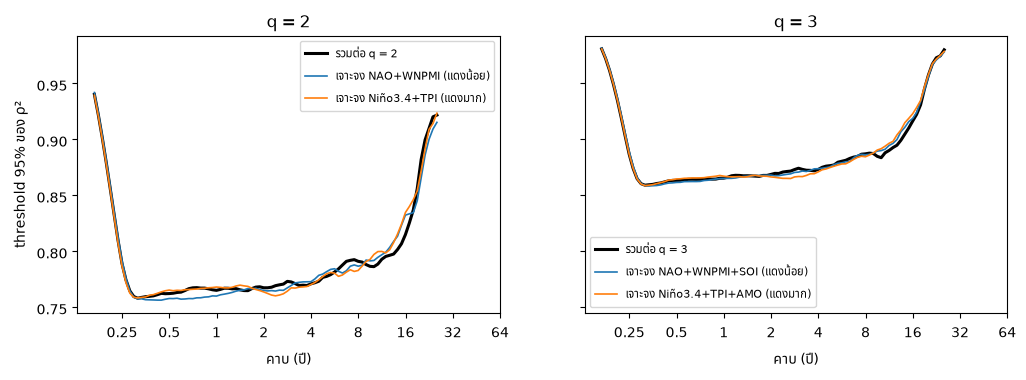

In [10]:
exact = json.loads(str(nul["exact"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, q in zip(axes, (2, 3)):
    ax.plot(periods, thr[q], "k", lw=2.2, label=f"รวมต่อ q = {q}")
    for lab, e in exact.items():
        if e["q"] == q:
            ax.plot(periods, e["per_scale"], lw=1.2,
                    label=f"เจาะจง {'+'.join(NAME[k] for k in e['subset'])} ({lab.split()[0]})")
    ax.set_xscale("log", base=2); ax.set_xticks(ticks); ax.set_xticklabels([f"{v:g}" for v in ticks]); ax.minorticks_off()
    ax.set_xlabel("คาบ (ปี)"); ax.legend(fontsize=8); ax.set_title(f"q = {q}")
axes[0].set_ylabel("threshold 95% ของ ρ²")
fig.savefig(FIGURES / "w5-pooled-vs-exact.png", dpi=130, bbox_inches="tight")

print("เจาะจง − รวม (ช่วงคาบ 0.5–16 ปี)")
for lab, e in exact.items():
    print(f"  {lab:12s} {'+'.join(NAME[k] for k in e['subset']):24s} มัธยฐาน {e['mid_median_diff']:+.3f} · มากสุด {e['mid_max_abs_diff']:.3f}")
assert all(abs(e["mid_median_diff"]) < 0.01 for e in exact.values())

ต่างกันระดับหนึ่งในร้อยของ ρ² — เล็กกว่าระยะห่างระหว่าง q ที่ติดกัน (~0.03–0.2) หลายเท่า
⇒ **ใช้ null รวมต่อ q ในขั้นค้นหาได้** และตามแผนเดิม W6 จะรัน null เจาะจงชุดเฉพาะชุดที่รายงานเป็นผลสุดท้าย

## 7. ลองกับข้อมูลจริง — ตัวอย่างสองลำดับ (ไม่ใช่ผลค้นหา)

- **ลำดับของเปเปอร์ต้นทาง**: Niño3.4 → +PDO → +NAO → +AMO → +TPI
- **ลำดับตามผล Q1 แถบ 2–7 ปี**: WNPMI → +DMI → +SOI

คิด PASC สองแบบเพื่อให้เห็นว่า threshold ที่ไม่ปรับตาม q ทำอะไรกับตัวเลข
(ก) ใช้ threshold ของ **q ตัวเอง** (วิธีของเรา) (ข) ใช้ threshold ของ **q = 1 ตลอด** (ถ้าลืมปรับ)

In [11]:
OURS = ["wnpmi", "dmi", "soi"]
PAPER_PASC = {1: 14.03, 2: 49.63, 3: 81.11, 4: 96.00}      # ค่าเฉลี่ย 82 สถานีของเปเปอร์ (source-paper-detail §4.2)

def evaluate(subset):
    q = len(subset)
    R2, _ = mwc_cached(cache, "y", subset)
    v = valid_mask(periods, coi, scales, DT_MONTHLY, y_fill, *[X_fill[k] for k in subset]) & np.isfinite(R2)
    sig_q, sig_1 = significance(R2, thr[q]), significance(R2, thr[1])
    out = {"R2": R2, "sig": sig_q, "valid": v, "mean_r2": float(R2[v].mean())}
    for b, band in BANDS.items():
        p_ = pasc(sig_q, v, periods, band)
        out[b] = dict(pasc=p_, p=empirical_p(p_, null[q][b]), pasc_fixed=pasc(sig_1, v, periods, band),
                      awc=awc(R2, sig_q, v, periods, band))
    return out

rows = {}
for name, seq in (("เปเปอร์", PAPER), ("Q1", OURS)):
    for q in range(1, len(seq) + 1):
        rows[(name, q)] = evaluate(seq[:q])

print(f"{'ลำดับ':8s} {'q':>2s} {'ชุด':30s} {'ρ² เฉลี่ย':>9s} │ {'PASC ทั้งระนาบ: ปรับ q (p) · ไม่ปรับ':>36s} │ {'แถบ 2–7 ปี: ปรับ q (p)':>22s}")
for (name, q), r in rows.items():
    seq = PAPER if name == "เปเปอร์" else OURS
    w, e = r["ทั้งระนาบ"], r["2–7 ปี"]
    print(f"{name:8s} {q:2d} {'+'.join(NAME[k] for k in seq[:q]):30s} {r['mean_r2']:9.3f} │ "
          f"{w['pasc']:6.1f}% ({w['p']:.3f}) · {w['pasc_fixed']:5.1f}%{'':>12s} │ {e['pasc']:6.1f}% ({e['p']:.3f})")

ลำดับ     q ชุด                            ρ² เฉลี่ย │ PASC ทั้งระนาบ: ปรับ q (p) · ไม่ปรับ │ แถบ 2–7 ปี: ปรับ q (p)
เปเปอร์   1 Niño3.4                            0.305 │   10.0% (0.026) ·  10.0%             │   13.3% (0.056)
เปเปอร์   2 Niño3.4+PDO                        0.485 │    7.5% (0.123) ·  31.3%             │    9.0% (0.164)
เปเปอร์   3 Niño3.4+PDO+NAO                    0.662 │    7.1% (0.142) ·  65.4%             │   11.6% (0.063)
เปเปอร์   4 Niño3.4+PDO+NAO+AMO                0.779 │    6.1% (0.221) ·  87.0%             │    8.8% (0.157)
เปเปอร์   5 Niño3.4+PDO+NAO+AMO+TPI            0.870 │    6.9% (0.116) ·  97.3%             │    4.8% (0.475)
Q1        1 WNPMI                              0.309 │   13.3% (0.003) ·  13.3%             │   32.2% (0.001)
Q1        2 WNPMI+DMI                          0.543 │   14.4% (0.002) ·  42.7%             │   26.9% (0.002)
Q1        3 WNPMI+DMI+SOI                      0.692 │   13.0% (0.004) ·  70.0%             │   16.3% (0.017)


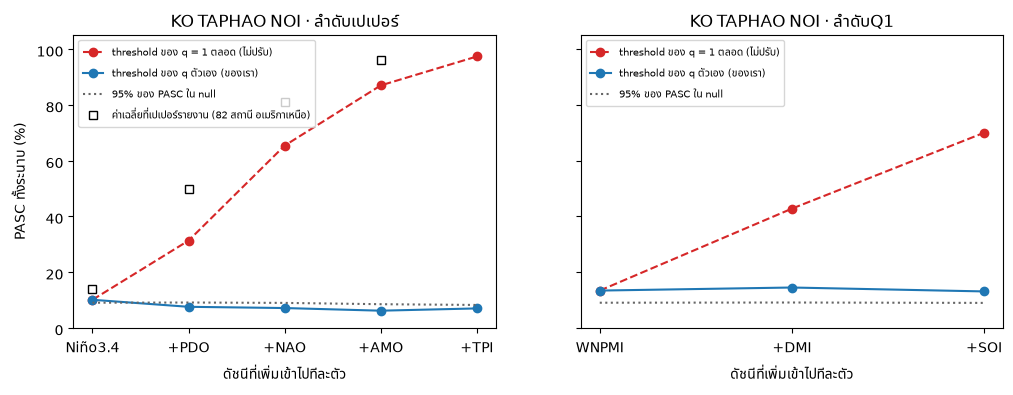

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (name, seq) in zip(axes, (("เปเปอร์", PAPER), ("Q1", OURS))):
    qs_ = list(range(1, len(seq) + 1))
    ax.plot(qs_, [rows[(name, q)]["ทั้งระนาบ"]["pasc_fixed"] for q in qs_], "o--", color="C3",
            label="threshold ของ q = 1 ตลอด (ไม่ปรับ)")
    ax.plot(qs_, [rows[(name, q)]["ทั้งระนาบ"]["pasc"] for q in qs_], "o-", color="C0",
            label="threshold ของ q ตัวเอง (ของเรา)")
    ax.plot(qs_, [np.percentile(null[q]["ทั้งระนาบ"], 95) for q in qs_], ":", color="0.4",
            label="95% ของ PASC ใน null")
    if name == "เปเปอร์":
        ax.plot(list(PAPER_PASC), list(PAPER_PASC.values()), "s", color="k", ms=6, mfc="none",
                label="ค่าเฉลี่ยที่เปเปอร์รายงาน (82 สถานี อเมริกาเหนือ)")
    ax.set_xticks(qs_)
    ax.set_xticklabels(["+".join(NAME[k] for k in seq[:q]) if q == 1 else f"+{NAME[seq[q-1]]}" for q in qs_])
    ax.set_xlabel("ดัชนีที่เพิ่มเข้าไปทีละตัว"); ax.set_title(f"KO TAPHAO NOI · ลำดับ{name}")
    ax.legend(fontsize=7.5, loc="upper left"); ax.set_ylim(0, 105)
axes[0].set_ylabel("PASC ทั้งระนาบ (%)")
fig.savefig(FIGURES / "w5-pasc-vs-q-preview.png", dpi=130, bbox_inches="tight")

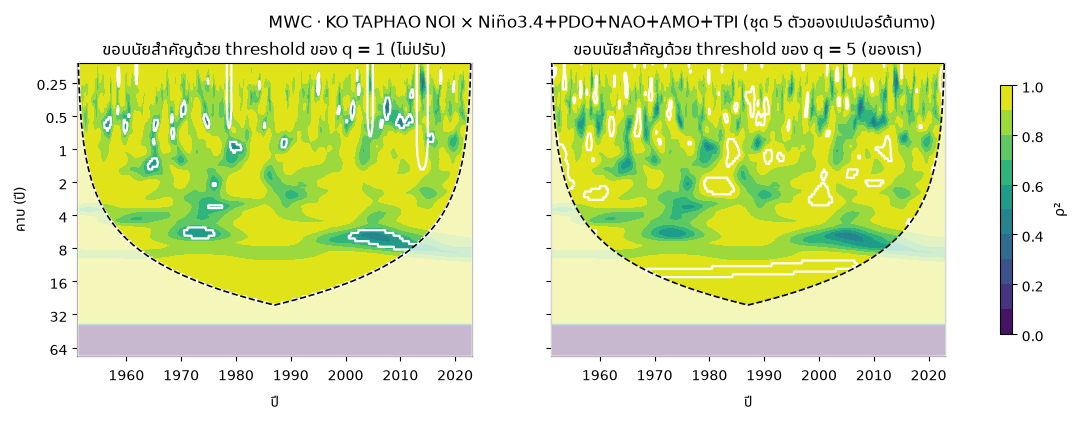

In [13]:
r5 = rows[("เปเปอร์", 5)]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, sig, ttl in ((axes[0], significance(r5["R2"], thr[1]), "ขอบนัยสำคัญด้วย threshold ของ q = 1 (ไม่ปรับ)"),
                     (axes[1], r5["sig"], "ขอบนัยสำคัญด้วย threshold ของ q = 5 (ของเรา)")):
    cf = plot_coherence(ax, t, periods, np.nan_to_num(r5["R2"]), coi, title=ttl, sig_mask=sig & r5["valid"])
axes[1].set_ylabel("")
fig.colorbar(cf, ax=axes, shrink=0.85, label="ρ²")
fig.suptitle("MWC · KO TAPHAO NOI × Niño3.4+PDO+NAO+AMO+TPI (ชุด 5 ตัวของเปเปอร์ต้นทาง)", y=1.02)
fig.savefig(FIGURES / "w5-mwc-paper-set.png", dpi=130, bbox_inches="tight")

**อ่านรูปซ้าย**: เกือบทั้งระนาบ "ผ่าน" เกณฑ์ของ q = 1 เส้นขาวจึงล้อม*เกาะที่ไม่ผ่าน*ไว้ (ไม่ใช่ล้อมที่ผ่าน)
รูปขวาใช้เกณฑ์ของ q = 5 เหลือหย่อมเล็ก ๆ กระจัดกระจายแบบที่ noise ทำได้เอง ⇒ ρ² ที่ดูสูงทั้งระนาบ (เหลือง ~0.9)
เป็นระดับปกติของ noise 5 ตัว ไม่ใช่การอธิบาย

## 8. ด่านตรวจ — คำนวณ threshold ของสถานีหลักใหม่ต้องได้เลขเดียวกับสคริปต์ทุกหลัก

surrogate ถูกแบ่งเป็นก้อน ก้อน k ใช้ seed + k ⇒ ผลขึ้นกับ (seed, nmc) เท่านั้น ไม่ขึ้นกับจำนวน worker
ด่านนี้รัน `threshold_mwc` ใหม่ทั้งหมดในโน้ตบุ๊ก (~1 นาที) แล้วเทียบกับไฟล์ **แบบเท่ากันเป๊ะ** ไม่ใช่ "ใกล้เคียง"

In [14]:
a_y, s_y = fit_ar1(y, y_fill)
ax_ = [fit_ar1(X[k], X_fill[k]) for k in xn]
assert abs(a_y - float(nul["a_y"][0])) < 1e-12 and np.allclose([a for a, _ in ax_], nul["a_x"], atol=1e-12)
t0 = time.perf_counter()
again = threshold_mwc(len(y), a_y, s_y, [a for a, _ in ax_], [s for _, s in ax_], qs=QS,
                      nmc=meta["nmc"], seed=meta["seed"], workers=20)
for q in QS:
    np.testing.assert_array_equal(again[q].per_scale, thr[q])
print(f"✅ threshold q = 1..5 ของ {MAIN} คำนวณใหม่ได้เลขเดียวกับ scripts/run_mwc_null.py ทุกหลัก "
      f"({time.perf_counter() - t0:.0f} วินาที)")

✅ threshold q = 1..5 ของ ko_taphao_noi คำนวณใหม่ได้เลขเดียวกับ scripts/run_mwc_null.py ทุกหลัก (66 วินาที)


## สรุป W5

**เครื่องมือถูกต้อง**
1. MWC ที่ q = 1 เท่ากับ WTC ต่างสูงสุด **7.8e-16** ทั้ง 8 ดัชนี (เกณฑ์ 1e-10) · Y = X1 + X2 ได้ MWC = 1 ทุกจุด ·
   การ normalize ขอบแกนสเกลยังหารกันหาย (9.5e-15) · เทสต์ 13 ตัวผ่าน
2. **ความกลัวเรื่อง Niño3.4 + SOI ไม่เกิดขึ้น** — cond สูงสุดในกรวย 198 · ทั้ง 218 ชุดไม่มีจุด NaN ในกรวยเลย
   (cond สูงสุด ~6×10⁴ ห่างเกณฑ์ 1e8 มาก) · จุดที่เสียจริงอยู่ที่คาบ ≥ 40 ปี นอก COI ทั้งหมด
3. null รวมต่อ q ใช้แทน null เจาะจงชุดได้ — ต่างกันมัธยฐานไม่เกิน 0.002 แม้ชุดที่ความแดงสุดโต่ง
4. threshold คำนวณใหม่ในโน้ตบุ๊กได้เลขเดียวกับสคริปต์ทุกหลัก

**⭐ ข้อค้นพบที่เปลี่ยนเรื่องเล่าของรายงาน**
5. threshold ของ MWC ขึ้นตาม q: **0.59 → 0.77 → 0.87 → 0.93 → 0.96** (เหมือนกันทั้งสามสถานี) —
   smoothing แบบ Grinsted เหลือข้อมูลอิสระในหน้าต่างแค่ ~4–6 ชิ้น การเพิ่มดัชนีจึงดัน ρ² ขึ้นเองแม้เป็น noise
6. ลำดับของเปเปอร์ต้นทางที่ KO TAPHAO NOI: **ถ้าไม่ปรับ threshold ตาม q ได้ PASC 10 → 31 → 65 → 87 → 97%
   ซึ่งหน้าตาเหมือนเส้นของเปเปอร์ (14 → 50 → 81 → 96)** · **ถ้าปรับ เหลือ 6–10% ทุกขั้น ไม่เกิน noise เลย**
   ⇒ อย่างน้อยที่สถานีนี้ "ยิ่งรวมยิ่งอธิบายได้" ทั้งเส้นอธิบายได้ด้วยการพองของ ρ² ตาม q
7. ลำดับตามผล Q1 (WNPMI → +DMI → +SOI) ยังมีนัยสำคัญทุกขั้น (p ≤ 0.004) **แต่ PASC ไม่เพิ่ม** (13.3 → 14.4 → 13.0%)
   ⇒ ยังไม่ผ่านเกณฑ์ +5% ของ Hu et al. (2017) · WNPMI ตัวเดียวทำงานเกือบทั้งหมด

**ข้อควรระวังก่อนเอาไปเขียน**
- ข้อ 6–7 เป็น**ตัวอย่างสองลำดับ** ไม่ใช่ผลค้นหา — คำตอบ Q3–Q5 ต้องรอการค้นครบ 218 ชุดใน W6
- เราไม่รู้ว่าเปเปอร์ต้นทางใช้ threshold แบบไหน (ไม่ได้รายงาน) และข้อมูลเขาเป็นอเมริกาเหนือรายปี ⇒ สิ่งที่พูดได้คือ
  "เส้นแบบเดียวกันเกิดได้จากการไม่ปรับ threshold" และ "AWC ต่ำสุด 0.938 ของเขาต่ำกว่า threshold q=5 ของ smoothing นี้"
  ไม่ใช่ "เขาทำผิด"
- Q6 (ดัชนีปลอม) ตอนนี้มีกรอบชัดขึ้น: เส้นสีแดงคือสิ่งที่ Q6 ต้องแสดงว่าเกิดได้จาก noise ล้วน